In [1]:
import importlib
import immsim
importlib.reload(immsim)
from immsim import immsim
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
#Rouler la simulation
ref = immsim()
ref.set_npr_policy(entry_cap = 252e3, renewal_rate = 0.8)
ref.set_imm_policy(entry_cap = 50e3, accept_rate = 0.1)
ref.proj(2025)


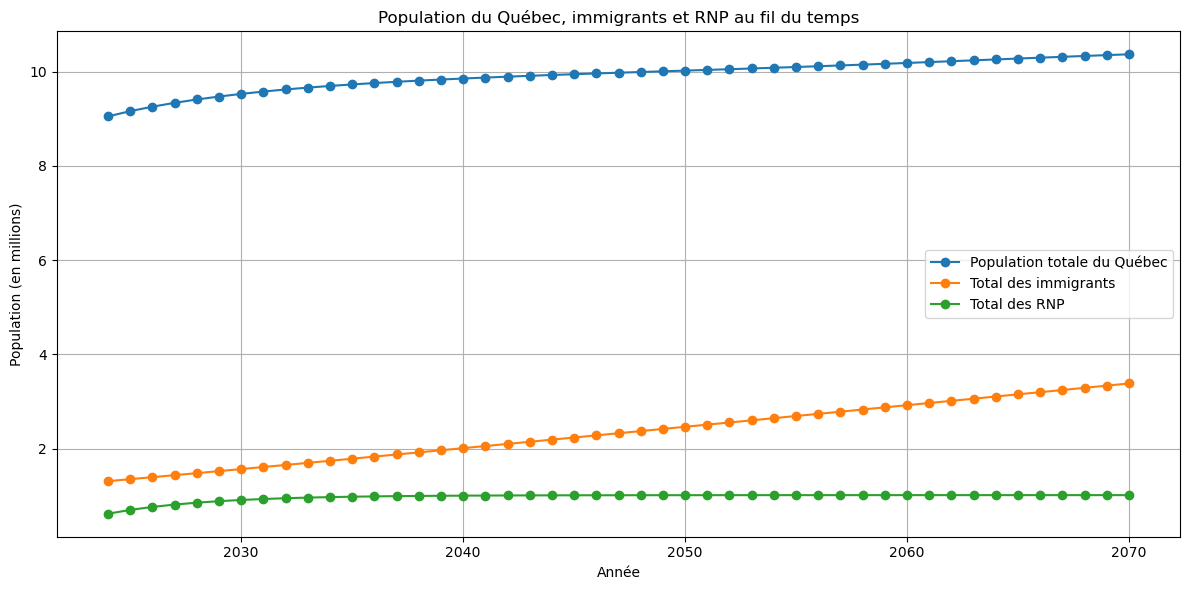

In [42]:
# Calculer la population totale, les immigrants et les RNP pour chaque année
total_population = ref.pop_sim.sum(axis=1)
total_immigrants = ref.imm_sim.groupby(level=0).sum().sum(axis=1)
total_nprs = ref.npr_sim.groupby(level=0).sum().sum(axis=1)

# Tracer le graphique
plt.figure(figsize=(12, 6))
plt.plot(total_population.index, total_population.values / 1e6, label='Population totale du Québec', marker='o')
plt.plot(total_immigrants.index, total_immigrants.values / 1e6, label='Total des immigrants', marker='o')
plt.plot(total_nprs.index, total_nprs.values / 1e6, label='Total des RNP', marker='o')

plt.title('Population du Québec, immigrants et RNP au fil du temps')
plt.xlabel('Année')
plt.ylabel('Population (en millions)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

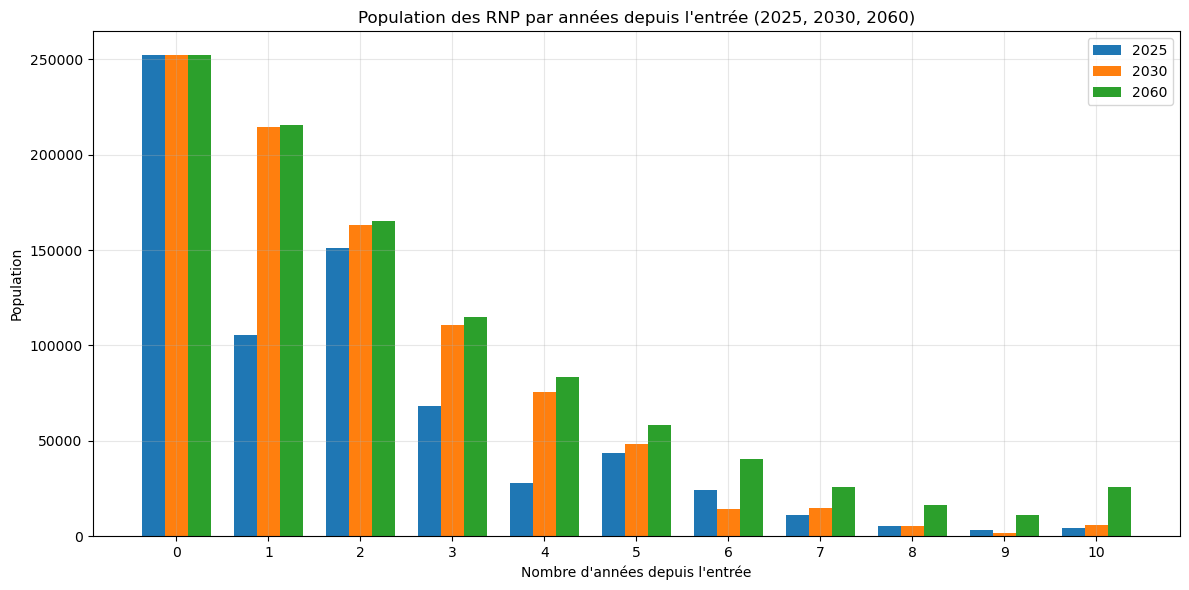

In [39]:
# Sélectionner les données pour les années spécifiques
years_to_plot = [2025, 2030, 2060]
npr_data = []

for year in years_to_plot:
    npr_pop = ref.npr_sim.loc[year, :]
    npr_data.append(npr_pop.sum(axis=1))

# Créer le DataFrame pour le graphique
df_plot = pd.DataFrame(npr_data, index=years_to_plot).T

# Créer le bar graph
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(df_plot.index))
width = 0.25

for i, year in enumerate(years_to_plot):
    ax.bar(x + i * width, df_plot[year], width, label=f'{year}')

ax.set_xlabel('Nombre d\'années depuis l\'entrée')
ax.set_ylabel('Population')
ax.set_title('Population des RNP par années depuis l\'entrée (2025, 2030, 2060)')
ax.set_xticks(x + width)
ax.set_xticklabels(df_plot.index)
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

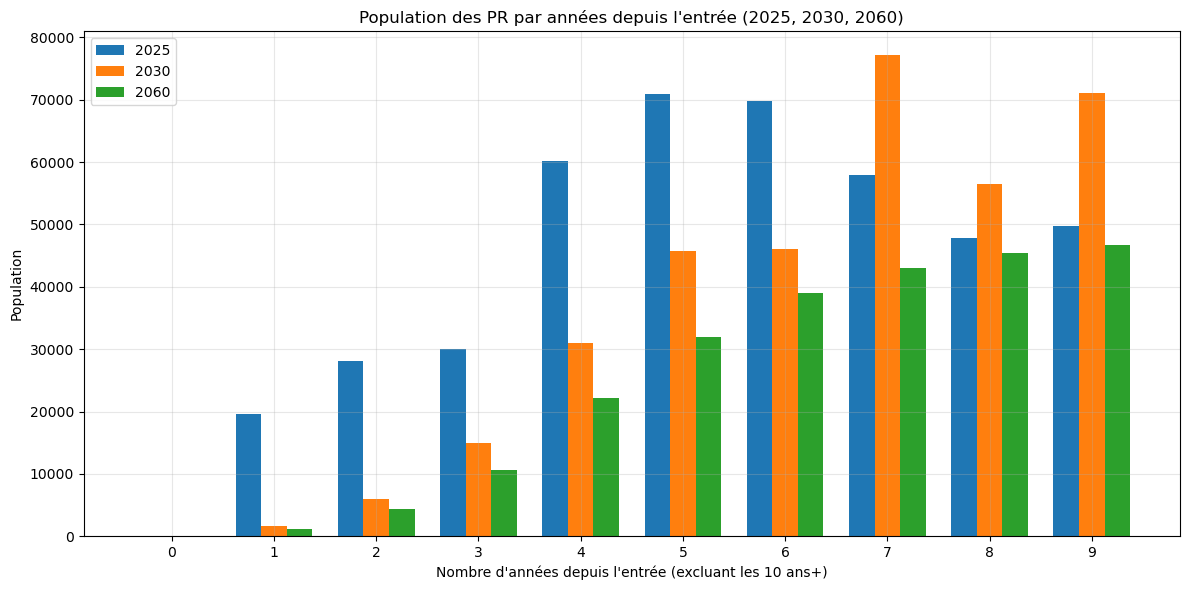

In [25]:
# Sélectionner les données pour les années spécifiques
years_to_plot = [2025, 2030, 2060]
imm_data = []

for year in years_to_plot:
    imm_pop = ref.imm_sim.loc[year, :].iloc[:-1]  # Exclure les 10 ans+
    imm_data.append(imm_pop.sum(axis=1))

# Créer le DataFrame pour le graphique
df_plot = pd.DataFrame(imm_data, index=years_to_plot).T

# Créer le bar graph
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(df_plot.index))
width = 0.25

for i, year in enumerate(years_to_plot):
    ax.bar(x + i * width, df_plot[year], width, label=f'{year}')

ax.set_xlabel('Nombre d\'années depuis l\'entrée (excluant les 10 ans+)')
ax.set_ylabel('Population')
ax.set_title('Population des PR par années depuis l\'entrée (2025, 2030, 2060)')
ax.set_xticks(x + width)
ax.set_xticklabels(df_plot.index)
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

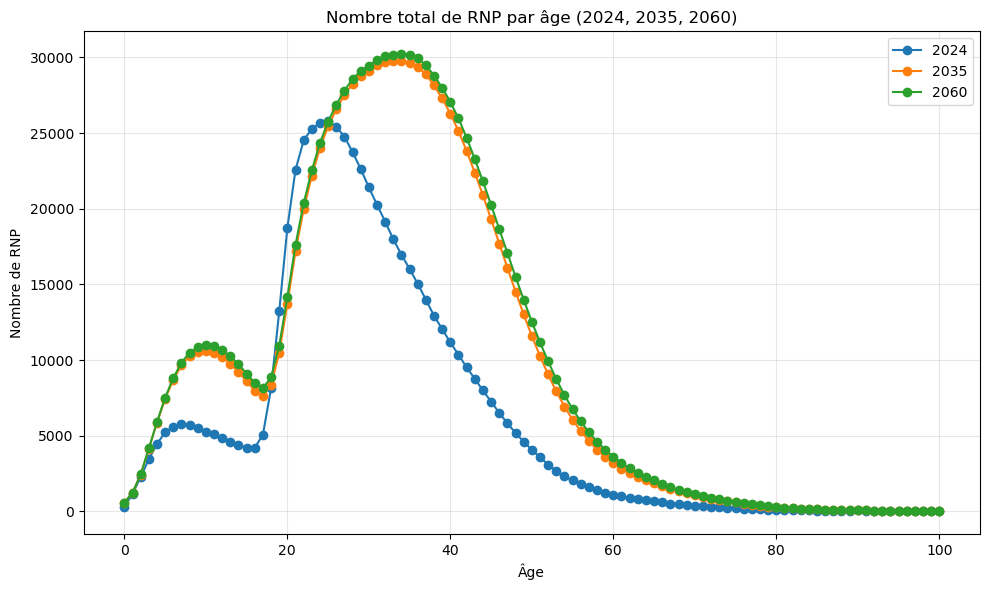

In [38]:
# Lignes pour plusieurs années: NPR total par âge
years = [2024, 2035, 2060]

plt.figure(figsize=(10, 6))
for y in years:
    s = ref.npr_sim.loc[(y, slice(None)), :].sum()  # somme sur toutes les durées
    plt.plot(s.index, s.values, marker='o', label=str(y))

plt.title('Nombre total de RNP par âge (2024, 2035, 2060)')
plt.xlabel('Âge')
plt.ylabel('Nombre de RNP')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

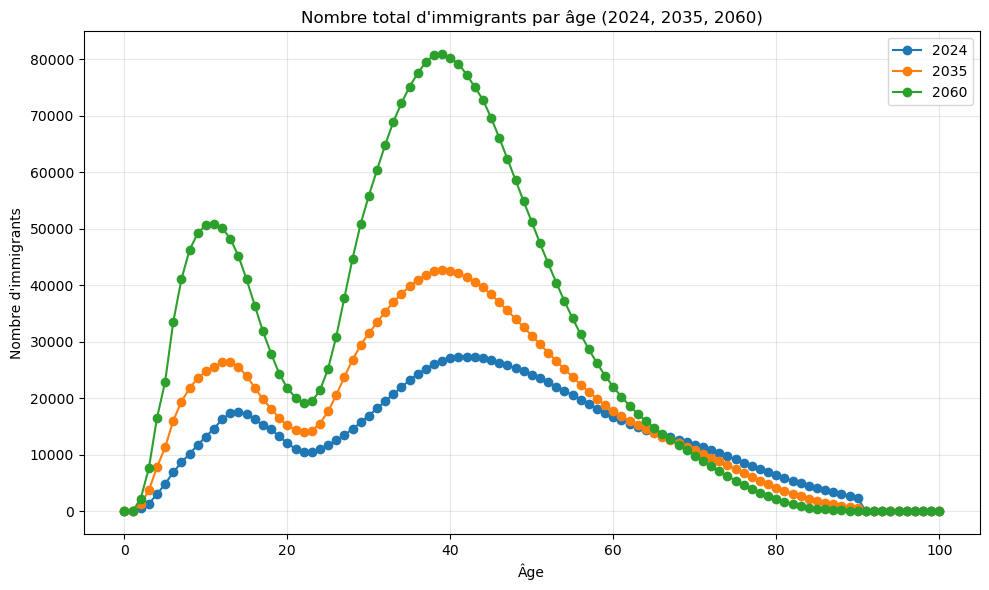

In [40]:
# Lignes pour plusieurs années: Immigrant total par âge
years = [2024, 2035, 2060]

plt.figure(figsize=(10, 6))
for y in years:
    s = ref.imm_sim.loc[(y, slice(None)), :].sum()  # somme sur toutes les durées
    plt.plot(s.index, s.values, marker='o', label=str(y))

plt.title('Nombre total d\'immigrants par âge (2024, 2035, 2060)')
plt.xlabel('Âge')
plt.ylabel('Nombre d\'immigrants')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()